In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("911.csv")
df.info

<bound method DataFrame.info of              lat        lng  \
0      40.297876 -75.581294   
1      40.258061 -75.264680   
2      40.121182 -75.351975   
3      40.116153 -75.343513   
4      40.251492 -75.603350   
...          ...        ...   
99487  40.132869 -75.333515   
99488  40.006974 -75.289080   
99489  40.115429 -75.334679   
99490  40.186431 -75.192555   
99491  40.207055 -75.317952   

                                                    desc      zip  \
0      REINDEER CT & DEAD END;  NEW HANOVER; Station ...  19525.0   
1      BRIAR PATH & WHITEMARSH LN;  HATFIELD TOWNSHIP...  19446.0   
2      HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...  19401.0   
3      AIRY ST & SWEDE ST;  NORRISTOWN; Station 308A;...  19401.0   
4      CHERRYWOOD CT & DEAD END;  LOWER POTTSGROVE; S...      NaN   
...                                                  ...      ...   
99487  MARKLEY ST & W LOGAN ST; NORRISTOWN; 2016-08-2...  19401.0   
99488  LANCASTER AVE & RITTENHOUSE PL; LOWE

In [3]:
df.head()

,lat,lng,desc,zip,title,timeStamp,twp,addr,e
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:40:00,NEW HANOVER,REINDEER CT & DEAD END,1
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:40:00,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 17:40:00,NORRISTOWN,HAWS AVE,1
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 17:40:01,NORRISTOWN,AIRY ST & SWEDE ST,1
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 17:40:01,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1


In [4]:
df.describe()

,lat,lng,zip,e
count,99492.000000,99492.000000,86637.000000,99492.0
mean,40.159526,-75.317464,19237.658298,1.0
std,0.094446,0.174826,345.344914,0.0
min,30.333596,-95.595595,17752.000000,1.0
25%,40.100423,-75.392104,19038.000000,1.0
50%,40.145223,-75.304667,19401.000000,1.0
75%,40.229008,-75.212513,19446.000000,1.0
max,41.167156,-74.995041,77316.000000,1.0


In [5]:
df.shape

(99492, 9)

In [6]:
df.isnull().sum()

lat              0
lng              0
desc             0
zip          12855
title            0
timeStamp        0
twp             43
addr           519
e                0
dtype: int64

##  Some Basic Question

##### 1. what is top 5 zip in 911 cells

In [7]:
df['zip'].value_counts().head(5)

zip
19401.0    6979
19464.0    6643
19403.0    4854
19446.0    4748
19406.0    3174
Name: count, dtype: int64

##### 2. what is top 5 twp in 911 cells

In [8]:
df['twp'].value_counts().head(5)

twp
LOWER MERION    8443
ABINGTON        5977
NORRISTOWN      5890
UPPER MERION    5227
CHELTENHAM      4575
Name: count, dtype: int64

#### 3. how many unque title code are there?

In [9]:
len(df['title'].unique())

110

## Create a new features

#### title ko split krne par

In [10]:
df['title']

0             EMS: BACK PAINS/INJURY
1            EMS: DIABETIC EMERGENCY
2                Fire: GAS-ODOR/LEAK
3             EMS: CARDIAC EMERGENCY
4                     EMS: DIZZINESS
                    ...             
99487    Traffic: VEHICLE ACCIDENT -
99488    Traffic: VEHICLE ACCIDENT -
99489               EMS: FALL VICTIM
99490           EMS: NAUSEA/VOMITING
99491    Traffic: VEHICLE ACCIDENT -
Name: title, Length: 99492, dtype: str

In [11]:
x = df['title'].iloc[0]

In [12]:
x

'EMS: BACK PAINS/INJURY'

In [13]:
x.split(':')[0]

'EMS'

In [14]:
df['Reason']= df['title'].apply(lambda title : title.split(':')[0])
df['Reason']

0            EMS
1            EMS
2           Fire
3            EMS
4            EMS
          ...   
99487    Traffic
99488    Traffic
99489        EMS
99490        EMS
99491    Traffic
Name: Reason, Length: 99492, dtype: str

#### 4. what is most common Reason for a 911  cells based off of new columns

In [15]:
df['Reason'].value_counts()

Reason
EMS        48877
Traffic    35695
Fire       14920
Name: count, dtype: int64

## 5. create a countplot of 911 call by Reason.....

C:\Users\nitin\AppData\Local\Temp\ipykernel_31796\2952671432.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Reason', data=df,palette='pastel')


<Axes: xlabel='Reason', ylabel='count'>

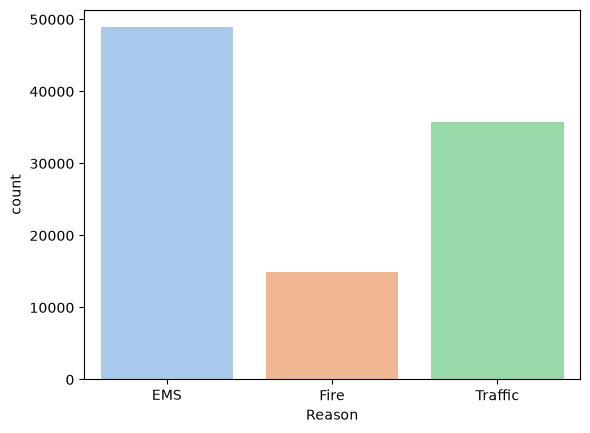

In [16]:
sns.countplot(x='Reason', data=df,palette='pastel')

### 4. what is data type of the objects in the timeStamp columns ?

In [17]:
type(df['timeStamp'].iloc[0])

str

### 5. to use pd.to_datetime to convert the column from string to datetime objects.........

In [18]:
df['timeStamp'] = pd.to_datetime(df['timeStamp'])

In [19]:
type(df['timeStamp'].iloc[0])

pandas.Timestamp

In [20]:
# hours 

time =df['timeStamp'].iloc[0]       #iloc is position based
time.hour

17

In [21]:
# year
time.year

2015

In [22]:
# day
time.day

10

In [23]:
df['Hour']= df['timeStamp'].apply( lambda time : time.hour)
df['Month']= df['timeStamp'].apply(lambda time : time.month)
df['Days of week'] = df['timeStamp'].apply(lambda time : time.dayofweek)

In [24]:
df['Hour']


0        17
1        17
2        17
3        17
4        17
         ..
99487    11
99488    11
99489    11
99490    11
99491    11
Name: Hour, Length: 99492, dtype: int64

##### dmap = { 0:'mon',1:'tue',2:'wed',3:'thus', 4:'fri', 5: 'sat'}

In [25]:
dmap = {
    0: 'mon',
    1: 'tue',
    2: 'wed',
    3: 'thu',
    4: 'fri',
    5: 'sat',
    6: 'sun'
}
df['Days of week'] = df['Days of week'].replace(dmap)

<Axes: xlabel='Days of week', ylabel='count'>

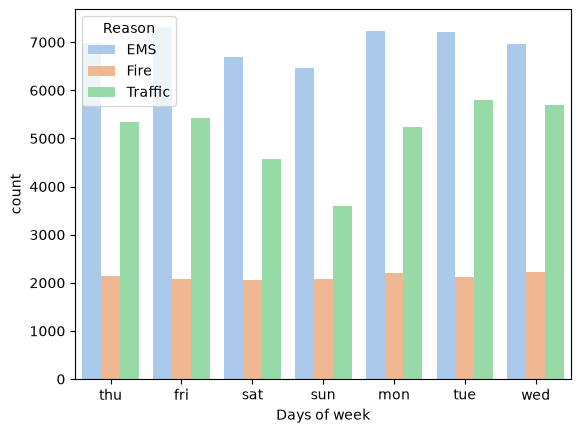

In [26]:
# chat of day of week and hue use to a reason 
sns.countplot(x='Days of week', data= df, hue='Reason', palette='pastel') 

<Axes: xlabel='Month', ylabel='count'>

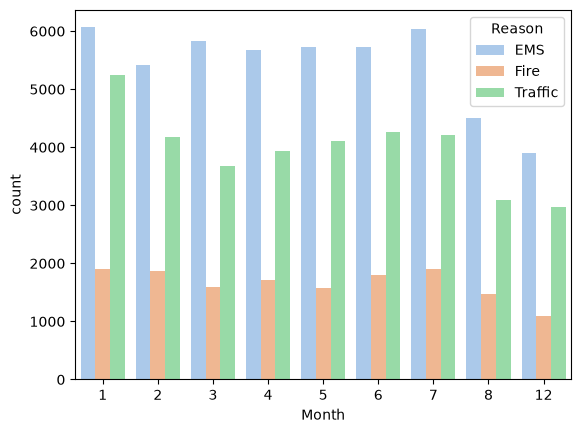

In [27]:
# same code month 
sns.countplot(x='Month', data= df, hue='Reason', palette='pastel')

In [28]:
bf_month= df.groupby('Month').count()

In [29]:
bf_month.head()

,lat,lng,desc,zip,title,timeStamp,twp,addr,e,Reason,Hour,Days of week
Month,,,,,,,,,,,,
1,13205,13205,13205,11527,13205,13205,13203,13096,13205,13205,13205,13205
2,11467,11467,11467,9930,11467,11467,11465,11396,11467,11467,11467,11467
3,11101,11101,11101,9755,11101,11101,11092,11059,11101,11101,11101,11101
4,11326,11326,11326,9895,11326,11326,11323,11283,11326,11326,11326,11326
5,11423,11423,11423,9946,11423,11423,11420,11378,11423,11423,11423,11423


###  month chart


C:\Users\nitin\AppData\Local\Temp\ipykernel_31796\188160817.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Month', palette='viridis')


<Axes: xlabel='Month', ylabel='count'>

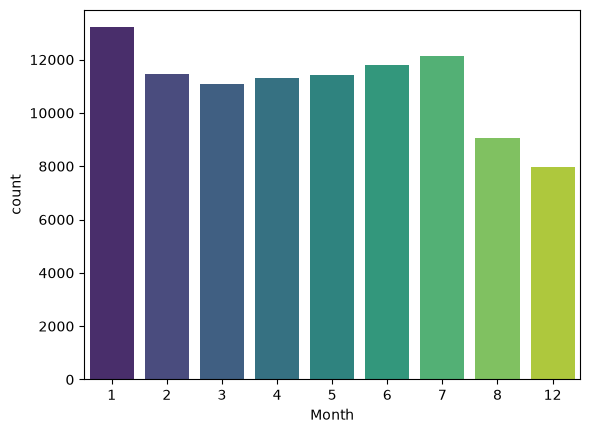

In [30]:
sns.countplot(data=df, x='Month', palette='viridis')

<Axes: xlabel='Month'>

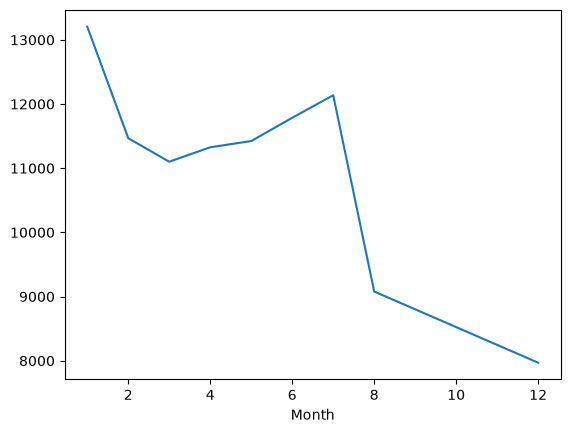

In [31]:
bf_month['lat'].plot()

In [32]:
# use to implot() for every month 

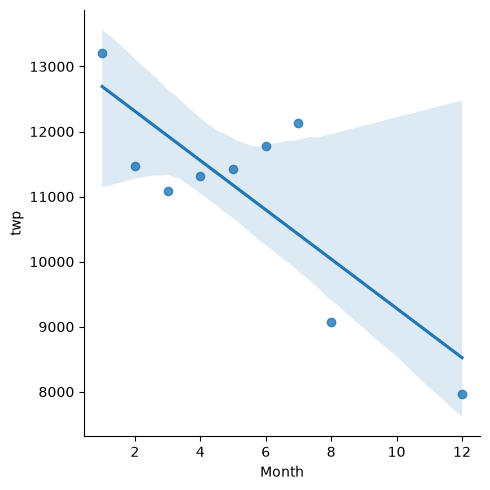

In [33]:
sns.lmplot(x='Month', y='twp', data= bf_month.reset_index())

####  create a new column for date

In [34]:
t = df['timeStamp'].iloc[0]

In [35]:
df['Date']= df['timeStamp'].apply(lambda t : t.date())       #add column 

In [36]:
t.date()

datetime.date(2015, 12, 10)

In [37]:
df.head()

,lat,lng,desc,zip,title,timeStamp,twp,addr,e,Reason,Hour,Month,Days of week,Date
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:40:00,NEW HANOVER,REINDEER CT & DEAD END,1,EMS,17,12,thu,2015-12-10
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:40:00,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1,EMS,17,12,thu,2015-12-10
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 17:40:00,NORRISTOWN,HAWS AVE,1,Fire,17,12,thu,2015-12-10
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 17:40:01,NORRISTOWN,AIRY ST & SWEDE ST,1,EMS,17,12,thu,2015-12-10
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 17:40:01,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1,EMS,17,12,thu,2015-12-10


#### now group by this date column with the count aggregate & create a plot of column in 911 cells......

In [38]:
Dte=df.groupby('Date').count()

<Axes: xlabel='Date'>

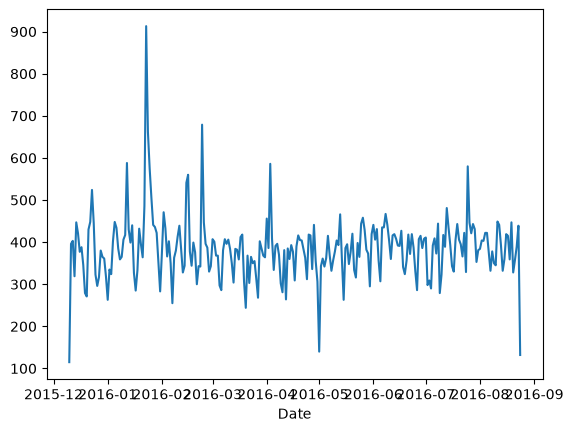

In [39]:
Dte['lat'].plot()

<Axes: xlabel='Date'>

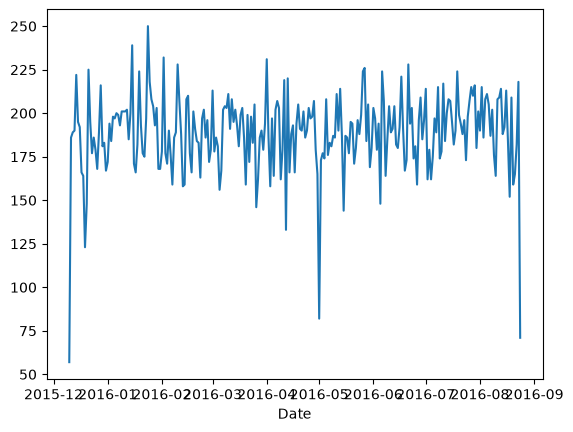

In [40]:
df[df['Reason']=='EMS'].groupby('Date').count()['lat'].plot()

In [41]:
df.head()

,lat,lng,desc,zip,title,timeStamp,twp,addr,e,Reason,Hour,Month,Days of week,Date
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:40:00,NEW HANOVER,REINDEER CT & DEAD END,1,EMS,17,12,thu,2015-12-10
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:40:00,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1,EMS,17,12,thu,2015-12-10
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 17:40:00,NORRISTOWN,HAWS AVE,1,Fire,17,12,thu,2015-12-10
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 17:40:01,NORRISTOWN,AIRY ST & SWEDE ST,1,EMS,17,12,thu,2015-12-10
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 17:40:01,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1,EMS,17,12,thu,2015-12-10


In [48]:
df.groupby(by=['Days of week','Hour']).count()

lat  lng  desc  zip  title  timeStamp  twp  addr    e  \
Days of week Hour                                                          
fri          0     275  275   275  248    275        275  275   275  275   
             1     235  235   235  200    235        235  235   232  235   
             2     191  191   191  165    191        191  191   191  191   
             3     175  175   175  164    175        175  175   175  175   
             4     201  201   201  184    201        201  201   201  201   
...                ...  ...   ...  ...    ...        ...  ...   ...  ...   
wed          19    686  686   686  590    686        686  686   682  686   
             20    668  668   668  597    668        668  668   662  668   
             21    575  575   575  508    575        575  574   572  575   
             22    490  490   490  432    490        490  490   485  490   
             23    335  335   335  294    335        335  334   335  335   

                   Reason  Month  Date  
Days of week Hour                       
fri          0        275    275   275  
             1        235    235   235  
             2        191    191   191  
             3        175    175   175  
             4        201    201   201  
...                   ...    ...   ...  
wed          19       686    686   686  
             20       668    668   668  
             21       575    575   575  
             22       490    490   490  
             23       335    335   335  

[168 rows x 12 columns]

<Axes: xlabel='Days of week,Hour'>

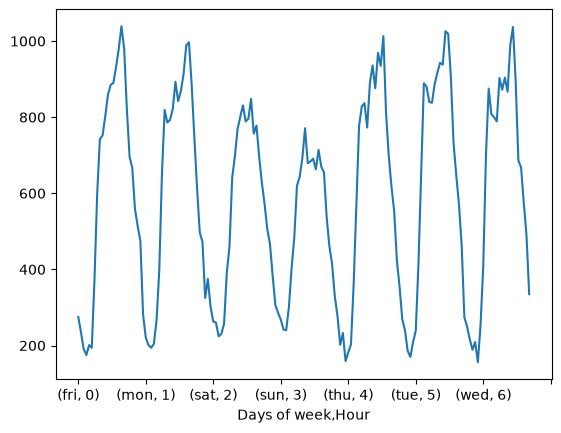

In [51]:
v=df.groupby(by=['Days of week','Hour']).count()
v['lat'].plot()

In [52]:
df.groupby(by=['Days of week','Hour']).count()['Reason']

Task was destroyed but it is pending!
task: <Task pending name='Task-801' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\nitin\AppData\Roaming\Python\Python314\site-packages\ipykernel\utils.py:57> wait_for=<Task finished name='Task-802' coro=<Kernel.shell_main() done, defined at C:\Users\nitin\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbase.py:597> exception=KeyError('c7bdf5df-2105-45ce-8ded-179564a272b5')> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\nitin\AppData\Roaming\Python\Python314\site-packages\zmq\eventloop\zmqstream.py:563]>
Task exception was never retrieved
future: <Task finished name='Task-802' coro=<Kernel.shell_main() done, defined at C:\Users\nitin\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbase.py:597> exception=KeyError('c7bdf5df-2105-45ce-8ded-179564a272b5')>
Traceback (most recent call last):
  File "C:\Users\nitin\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbas

Days of week  Hour
fri           0       275
              1       235
              2       191
              3       175
              4       201
                     ... 
wed           19      686
              20      668
              21      575
              22      490
              23      335
Name: Reason, Length: 168, dtype: int64

In [64]:
dayHours=df.groupby(by=['Days of week','Hour']).count()['Reason'].unstack()
dayHours

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Days of week,,,,,,,,,,,,,,,,,,,,,
fri,275,235,191,175,201,194,372,598,742,752,...,932,980,1039,980,820,696,667,559,514,474
mon,282,221,201,194,204,267,397,653,819,786,...,869,913,989,997,885,746,613,497,472,325
sat,375,301,263,260,224,231,257,391,459,640,...,789,796,848,757,778,696,628,572,506,467
sun,383,306,286,268,242,240,300,402,483,620,...,684,691,663,714,670,655,537,461,415,330
thu,278,202,233,159,182,203,362,570,777,828,...,876,969,935,1013,810,698,617,553,424,354
tue,269,240,186,170,209,239,415,655,889,880,...,943,938,1026,1019,905,731,647,571,462,274
wed,250,216,189,209,156,255,410,701,875,808,...,904,867,990,1037,894,686,668,575,490,335


<Axes: xlabel='Hour', ylabel='Days of week'>

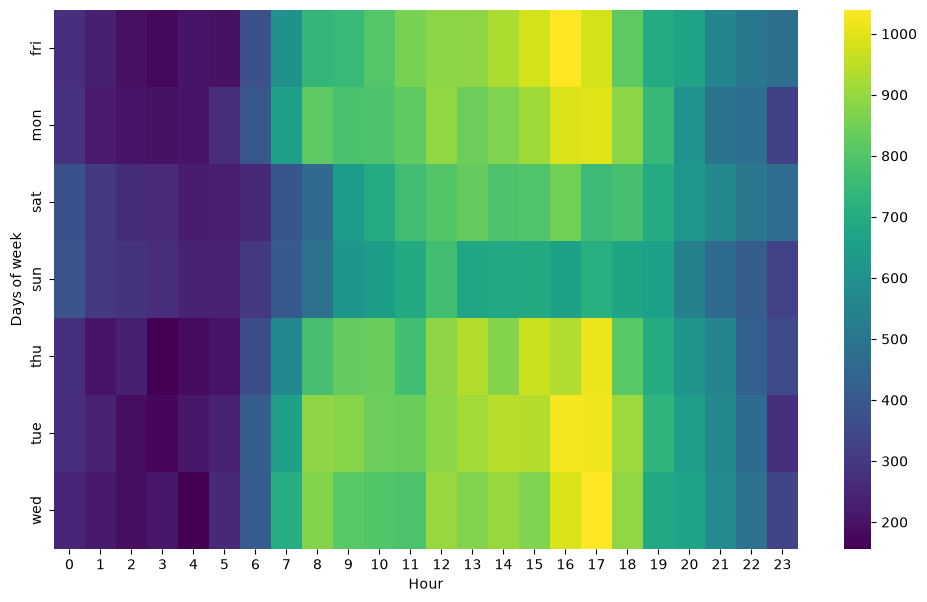

In [66]:
plt.figure(figsize=(12,7))
sns.heatmap(dayHours, cmap='viridis')

In [67]:
dayHours.head()

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Days of week,,,,,,,,,,,,,,,,,,,,,
fri,275,235,191,175,201,194,372,598,742,752,...,932,980,1039,980,820,696,667,559,514,474
mon,282,221,201,194,204,267,397,653,819,786,...,869,913,989,997,885,746,613,497,472,325
sat,375,301,263,260,224,231,257,391,459,640,...,789,796,848,757,778,696,628,572,506,467
sun,383,306,286,268,242,240,300,402,483,620,...,684,691,663,714,670,655,537,461,415,330
thu,278,202,233,159,182,203,362,570,777,828,...,876,969,935,1013,810,698,617,553,424,354


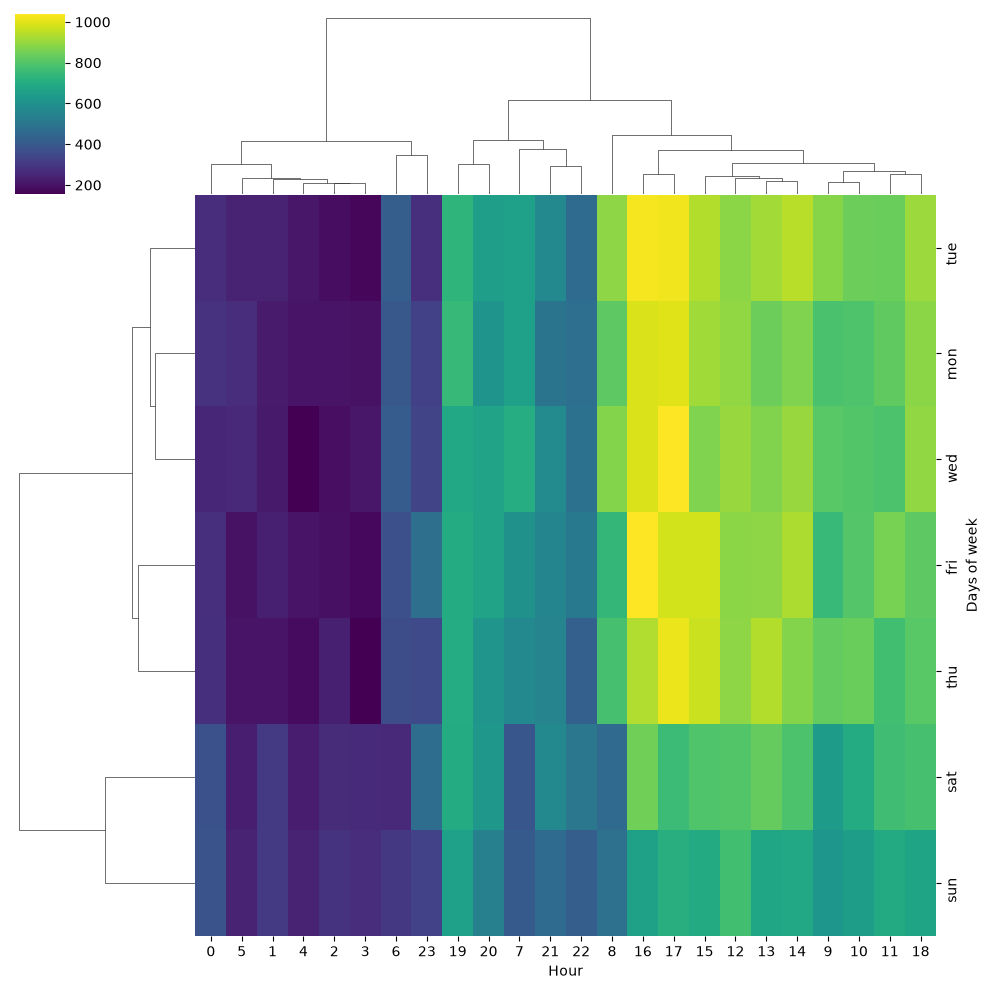

In [68]:
sns.clustermap(dayHours, cmap='viridis')

<Axes: xlabel='Hour', ylabel='Days of week'>

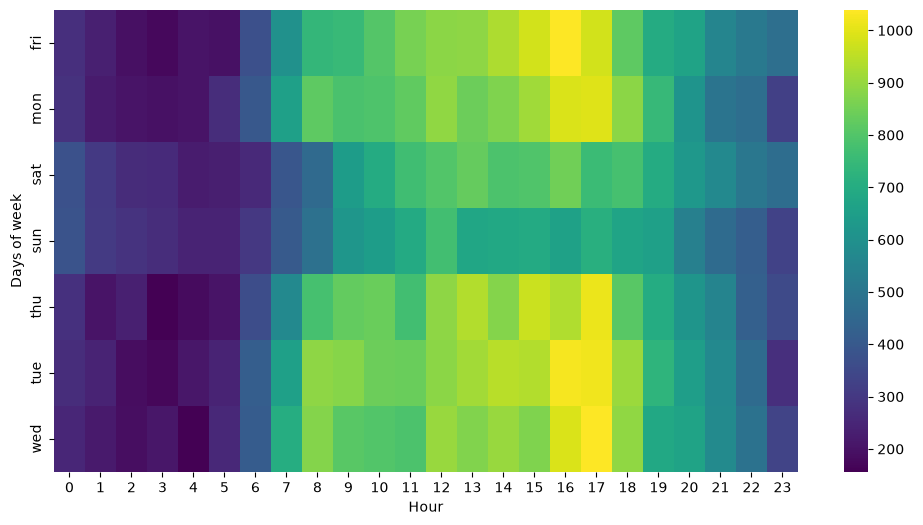

In [70]:
plt.figure(figsize=(12,6))
sns.heatmap(dayHours,cmap='viridis')